# Parte 1

In [1]:
import numpy as np
import pandas as pd
import matplotlib as plt
import funcoes_aux_proj_apr_supervisionada

dados = pd.read_pickle('Xsup.pkl')
dados

,Skeleton_Sequence,Exercise_Id,Patient_ID,Compensação_Ombro,Compensação_Tronco,Compensação_Cabeça
0,"[[-0.025484836, -0.572286367, -0.011180799, -0...",E2,18,0,1,1
1,"[[0.1457298099994659, -0.177351892, 0.17020170...",E4,17,1,1,1
2,"[[0.019437663, -0.542804241, 0.032009996473789...",E5,15,0,0,1
3,"[[-0.000282567, -0.572014868, 0.014581724, -0....",E1,2,1,1,1
4,"[[-0.067052722, -0.077053629, -0.050083861, -0...",E4,8,1,0,1
...,...,...,...,...,...,...
1254,"[[0.062138677, -0.535513282, 0.077235512, -0.5...",E5,3,1,0,1
1255,"[[0.061319716, -0.557576954, 0.074186742, -0.5...",E5,11,1,0,1
1256,"[[-0.009194537, -0.536099017, 0.00539052, -0.5...",E3,1,0,1,0
1257,"[[-0.045662187, -0.582765043, -0.031464174, -0...",E2,11,0,1,1


## R1a) - Função de regressão linear

In [2]:
import numpy as np 

def regressao_linear (X, Y):
    X = np.array(X)
    Y = np.array(Y)
    
    theta, residuals, rank, s = np.linalg.lstsq(X, Y, rcond=None)
    
    beta_0 = theta[0]
    beta = theta[1:]
    
    return beta, beta_0

## R1b)

In [3]:
sequencias = dados[(dados["Exercise_Id"] == "E5") & (dados["Patient_ID"] == 4)]

n = len(sequencias)
n_treino = int(n*0.8)

treino = sequencias.iloc[:n_treino]
teste = sequencias.iloc[n_treino:]

print("Total de Sequências:", n)
print("Sequências de Treino:", len(treino))
print("Sequências de Teste:", len(teste))


Total de Sequências: 10
Sequências de Treino: 8
Sequências de Teste: 2


## R1c)

In [4]:
X_treino_lista = []
Y_treino_lista = []

Nome_coluna = "Skeleton_Sequence"

for _, row in treino.iterrows():
    seq = np.array(row[Nome_coluna]) if Nome_coluna in treino.columns else np.array(row)
    X_treino_lista.append(seq[:-1, :])
    Y_treino_lista.append(seq[1:, :])
    
X_treino_raw = np.vstack(X_treino_lista)
Y_treino_raw = np.vstack(Y_treino_lista)

X_treino = np.column_stack((np.ones(X_treino_raw.shape[0]), X_treino_raw))

print("Dimensão de X_treino:", X_treino.shape)
print("Dimensão de Y_treino:", Y_treino_raw.shape)
    

Dimensão de X_treino: (279, 67)
Dimensão de Y_treino: (279, 66)


## R1d)

In [5]:
X_teste_lista = []
Y_teste_lista = []

NOME_COLUNA = "Skeleton_Sequence" 

for _, row in teste.iterrows():
    seq = np.array(row[NOME_COLUNA])
    X_teste_lista.append(seq[:-1, :])
    Y_teste_lista.append(seq[1:, :])
    
X_teste_raw = np.vstack(X_teste_lista)
Y_teste_raw = np.vstack(Y_teste_lista)

# Adicionar obrigatoriamente a coluna de 1s para o beta_0 no conjunto de teste também
X_teste = np.column_stack((np.ones(X_teste_raw.shape[0]), X_teste_raw))

print("Dimensão de X_teste:", X_teste.shape)
print("Dimensão de Y_teste:", Y_teste_raw.shape)


Dimensão de X_teste: (67, 67)
Dimensão de Y_teste: (67, 66)


## R1e)

In [6]:
def calcular_metricas(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    sse = np.sum((y_true - y_pred) ** 2)
    
    y_mean = np.mean(y_true, axis=0)
    sst = np.sum((y_true - y_mean) ** 2)
    
    r2 = 1 - (sse / sst)
    
    return sse, r2

## R2a)

In [7]:
beta, beta_0 = regressao_linear(X_treino, Y_treino_raw)

print("Dimensões de beta:", beta.shape)
print("Dimensões de beta_0:", beta_0.shape)


Dimensões de beta: (66, 66)
Dimensões de beta_0: (66,)


## R2b)

In [8]:
Y_treino_pred = X_treino_raw @ beta + beta_0

sse_treino, r2_treino = calcular_metricas(Y_treino_raw, Y_treino_pred)

print(f"SSE Global: {sse_treino:.4f}")
print(f"R^2 Global: {r2_treino:.4f}")


SSE Global: 1.4345
R^2 Global: 0.9666


/var/folders/d7/36p1n7fd4c7fdwkb6r3rvbkw0000gn/T/ipykernel_20670/2144122150.py:1: RuntimeWarning: divide by zero encountered in matmul
  Y_treino_pred = X_treino_raw @ beta + beta_0
/var/folders/d7/36p1n7fd4c7fdwkb6r3rvbkw0000gn/T/ipykernel_20670/2144122150.py:1: RuntimeWarning: overflow encountered in matmul
  Y_treino_pred = X_treino_raw @ beta + beta_0
/var/folders/d7/36p1n7fd4c7fdwkb6r3rvbkw0000gn/T/ipykernel_20670/2144122150.py:1: RuntimeWarning: invalid value encountered in matmul
  Y_treino_pred = X_treino_raw @ beta + beta_0


## R2c)

In [9]:
Y_teste_pred = X_teste_raw @ beta + beta_0

sse_teste, r2_teste = calcular_metricas(Y_teste_raw, Y_teste_pred)

print(f"SSE Global: {sse_teste:.4f}")
print(f"R^2 Global: {r2_teste:.4f}")

erros_por_keypoint = np.sum((Y_teste_raw - Y_teste_pred) ** 2, axis=0)
top_erros_idx = np.argsort(erros_por_keypoint)[::-1][:5]

print(f"\nOs 5 índices (0-65) com maior erro (SSE) acumulado no teste: {top_erros_idx}")


SSE Global: 0.7344
R^2 Global: 0.9291

Os 5 índices (0-65) com maior erro (SSE) acumulado no teste: [63 59 53 55 51]


/var/folders/d7/36p1n7fd4c7fdwkb6r3rvbkw0000gn/T/ipykernel_20670/323876059.py:1: RuntimeWarning: divide by zero encountered in matmul
  Y_teste_pred = X_teste_raw @ beta + beta_0
/var/folders/d7/36p1n7fd4c7fdwkb6r3rvbkw0000gn/T/ipykernel_20670/323876059.py:1: RuntimeWarning: overflow encountered in matmul
  Y_teste_pred = X_teste_raw @ beta + beta_0
/var/folders/d7/36p1n7fd4c7fdwkb6r3rvbkw0000gn/T/ipykernel_20670/323876059.py:1: RuntimeWarning: invalid value encountered in matmul
  Y_teste_pred = X_teste_raw @ beta + beta_0


## R2d)

In [10]:
from funcoes_aux_proj_apr_supervisionada import visualize_sequences
from IPython.display import display

NOME_COLUNA = "Skeleton_Sequence" 
seq_verdadeira = np.array(teste.iloc[0][NOME_COLUNA])

X_seq_teste = seq_verdadeira[:-1, :]
Y_seq_teste_pred = X_seq_teste @ beta + beta_0

anim_true = visualize_sequences(seq_verdadeira[1:], title="Sequência Verdadeira (E5)")

anim_pred = visualize_sequences(Y_seq_teste_pred, title="Sequência Prevista (E5)")

display(anim_true)
display(anim_pred)

Total Frames to Animate: 34


/var/folders/d7/36p1n7fd4c7fdwkb6r3rvbkw0000gn/T/ipykernel_20670/607330769.py:8: RuntimeWarning: divide by zero encountered in matmul
  Y_seq_teste_pred = X_seq_teste @ beta + beta_0
/var/folders/d7/36p1n7fd4c7fdwkb6r3rvbkw0000gn/T/ipykernel_20670/607330769.py:8: RuntimeWarning: overflow encountered in matmul
  Y_seq_teste_pred = X_seq_teste @ beta + beta_0
/var/folders/d7/36p1n7fd4c7fdwkb6r3rvbkw0000gn/T/ipykernel_20670/607330769.py:8: RuntimeWarning: invalid value encountered in matmul
  Y_seq_teste_pred = X_seq_teste @ beta + beta_0


Total Frames to Animate: 34


# Parte II

## R3b)

In [11]:
paciente_4 = dados[(dados["Patient_ID"] == 4)].reset_index(drop=True)

n_seqs = len(paciente_4)
n_treino_p4 = int(n_seqs * 0.8)

treino_p4 = paciente_4.iloc[:n_treino_p4]
teste_p4 = paciente_4.iloc[n_treino_p4:]

print(f"Total de sequências do paciente 4: {n_seqs}")
print(f"Total de sequências de treino do paciente 4: {len(treino_p4)}")
print(f"Total de sequências de teste do paciente 4: {len(teste_p4)}")

mapeamento_exercicios = {'E1': 0, 'E2': 1, 'E3': 2, 'E4': 3, 'E5': 4}

Total de sequências do paciente 4: 70
Total de sequências de treino do paciente 4: 56
Total de sequências de teste do paciente 4: 14


## R3c)

In [12]:
from funcoes_aux_proj_apr_supervisionada import extrair_atributos 

def criar_matrizes_atributos(subset_df):
    X_lista = []
    Y_lista = []
    
    for _, row in subset_df.iterrows():
        seq = np.array(row["Skeleton_Sequence"])
        atributos = extrair_atributos(seq)
        X_lista.append(atributos)
        Y_lista.append(mapeamento_exercicios[row["Exercise_Id"]])
        
    return np.array(X_lista), np.array(Y_lista)

X_train, y_train = criar_matrizes_atributos(treino_p4)
X_teste, y_teste = criar_matrizes_atributos(teste_p4)

print("Dimensão de X_train:", X_train.shape)
print("Dimensão de X_teste:", X_teste.shape)
print("Dimensão de y_train:", y_train.shape)


Dimensão de X_train: (56, 268)
Dimensão de X_teste: (14, 268)
Dimensão de y_train: (56,)


## R3d)

In [13]:
from sklearn.metrics import confusion_matrix, balanced_accuracy_score

def avaliar_classificacao(y_true, y_pred):
    
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    mat_conf = confusion_matrix(y_true, y_pred)
    
    return bal_acc, mat_conf

## R4a)

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
from arvore_decisao import ArvoreDecisao

os.makedirs("Figuras", exist_ok=True)

profundidades = [1, 2, 3, 4, 5]
resultados_arvore = []

for profundidade in profundidades:
    
    arvore = ArvoreDecisao(profundidade_maxima=profundidade)
    arvore.fit(X_train, y_train)
    
    y_pred_train = arvore.predict(X_train)
    y_pred_test = arvore.predict(X_teste)
    
    acc_train, _ = avaliar_classificacao(y_train, y_pred_train)
    acc_test, _ = avaliar_classificacao(y_teste, y_pred_test)
    
    resultados_arvore.append((profundidade, acc_train, acc_test))
    print(f"Profundidade Max: {profundidade} | Treino Acc: {acc_train:.4f} | Teste Acc: {acc_test:.4f}")

Profundidade Max: 1 | Treino Acc: 0.3889 | Teste Acc: 0.4000
Profundidade Max: 2 | Treino Acc: 0.7489 | Teste Acc: 0.8000
Profundidade Max: 3 | Treino Acc: 0.9667 | Teste Acc: 0.9500
Profundidade Max: 4 | Treino Acc: 1.0000 | Teste Acc: 0.9500
Profundidade Max: 5 | Treino Acc: 1.0000 | Teste Acc: 0.9500


## R4b)

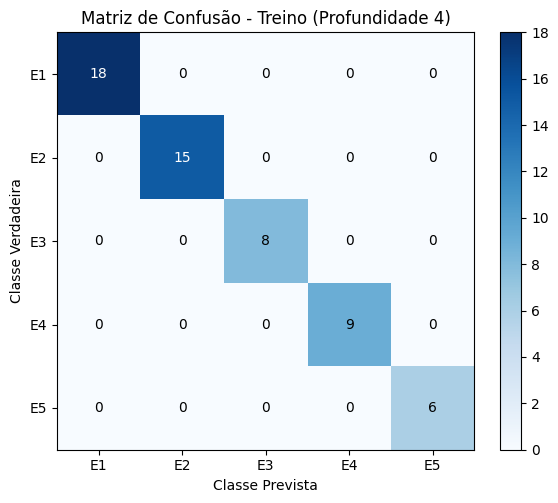

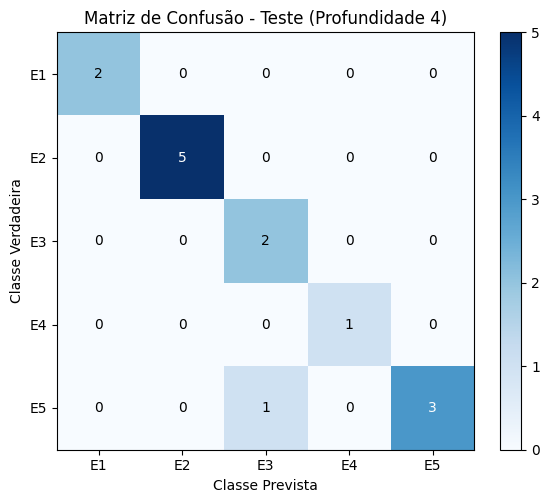

In [22]:
import os
import matplotlib.pyplot as plt
import numpy as np
from arvore_decisao import ArvoreDecisao

os.makedirs("Figuras", exist_ok=True)

def plot_e_guardar_matriz_confusao(y_true, y_pred, titulo, nome_ficheiro):
    _, matriz = avaliar_classificacao(y_true, y_pred)
    
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(matriz, interpolation='nearest', cmap=plt.cm.Blues)
    ax.set_title(titulo)
    fig.colorbar(im, ax=ax)
    
    classes = ['E1', 'E2', 'E3', 'E4', 'E5']
    tick_marks = np.arange(len(classes))
    ax.set_xticks(tick_marks)
    ax.set_xticklabels(classes)
    ax.set_yticks(tick_marks)
    ax.set_yticklabels(classes)
    
    # Escrever os valores numéricos dentro de cada célula da matriz
    limiar_cor = matriz.max() / 2.0
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            ax.text(j, i, format(matriz[i, j], 'd'),
                    ha="center", va="center",
                    color="white" if matriz[i, j] > limiar_cor else "black")
    
    ax.set_ylabel('Classe Verdadeira')
    ax.set_xlabel('Classe Prevista')
    plt.tight_layout()
    
    caminho = os.path.join("Figuras", nome_ficheiro)
    plt.savefig(caminho, dpi=300)
    plt.show()

PROFUNDIDADE = 4

arvore_final = ArvoreDecisao(profundidade_maxima=PROFUNDIDADE)
arvore_final.fit(X_train, y_train)

plot_e_guardar_matriz_confusao(
    y_train, arvore_final.predict(X_train),
    f"Matriz de Confusão - Treino (Profundidade {PROFUNDIDADE})",
    "PartII4b_treino.jpg"
)

plot_e_guardar_matriz_confusao(
    y_teste, arvore_final.predict(X_teste),
    f"Matriz de Confusão - Teste (Profundidade {PROFUNDIDADE})",
    "PartII4b_teste.jpg"
)

## R4c)

In [21]:
from funcoes_aux_proj_apr_supervisionada import imprimir_arvore, obter_nomes_atributos

arvore_prof4 = ArvoreDecisao(profundidade_maxima=4)
arvore_prof4.fit(X_train, y_train)

nomes_atributos = obter_nomes_atributos()
idx_to_class = {
    0: 'E1 (Escovar Cabelo)',
    1: 'E2 (Lavar Dentes)',
    2: 'E3 (Lavar Cara)',
    3: 'E4 (Calçar Meias)',
    4: 'E5 (Levantar Joelhos)'
}

imprimir_arvore(arvore_prof4.raiz, profundidade=0, nomes_atributos=nomes_atributos, idx_to_class=idx_to_class)


├── [cotovelo_esquerdo_desvio_padrao_vel_y <= 0.006174]
  [Verdadeiro]
    ├── [amplitude_movimento_joelho_esquerdo <= 10.920034]
      [Verdadeiro]
        ├── [cotovelo_esquerdo_desvio_padrao_vel_x <= 0.004590]
          [Verdadeiro]
            ├── [orelha_esquerda_media_vel_x <= -0.000070]
              [Verdadeiro]
                └── Folha: E1 (Escovar Cabelo)
              [Falso]
                └── Folha: E2 (Lavar Dentes)
          [Falso]
            └── Folha: E1 (Escovar Cabelo)
      [Falso]
        └── Folha: E2 (Lavar Dentes)
  [Falso]
    ├── [nariz_desvio_padrao_vel_y <= 0.007746]
      [Verdadeiro]
        ├── [punho_direito_desvio_padrao_vel_y <= 0.011275]
          [Verdadeiro]
            ├── [ombro_esquerdo_media_vel_y <= -0.001668]
              [Verdadeiro]
                └── Folha: E1 (Escovar Cabelo)
              [Falso]
                └── Folha: E5 (Levantar Joelhos)
          [Falso]
            └── Folha: E3 (Lavar Cara)
      [Falso]
        └── Folha:

# Parte III

## R5a)

--- R5.a) NAIVE BAYES (FEATURES MANUAIS) ---
Balanced Accuracy Treino: 0.9111
Balanced Accuracy Teste:  0.9000


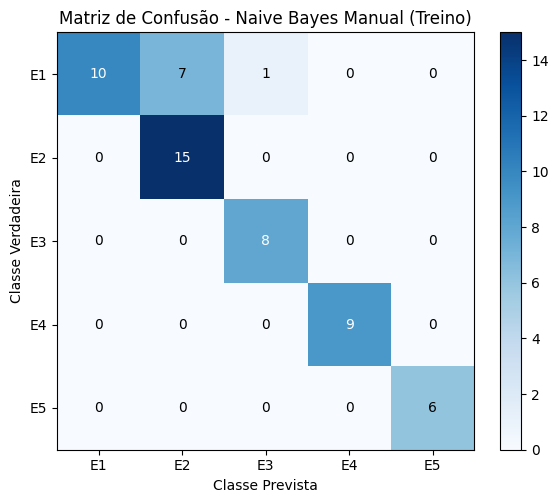

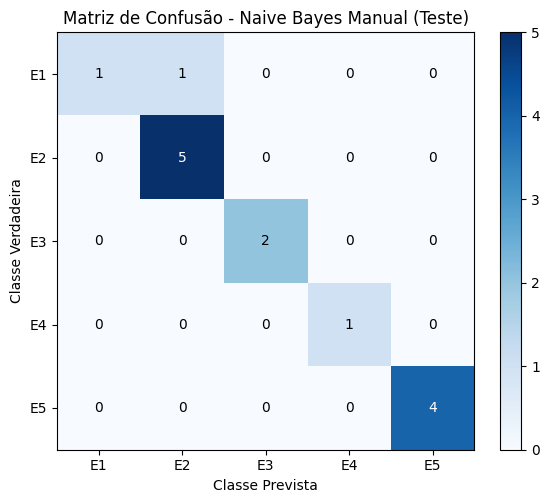

In [23]:
from sklearn.naive_bayes import GaussianNB

nb_manual = GaussianNB()
nb_manual.fit(X_train, y_train)

y_pred_train_nb = nb_manual.predict(X_train)
y_pred_test_nb = nb_manual.predict(X_teste)

acc_train_nb, mat_train_nb = avaliar_classificacao(y_train, y_pred_train_nb)
acc_test_nb, mat_test_nb = avaliar_classificacao(y_teste, y_pred_test_nb)

print("--- R5.a) NAIVE BAYES (FEATURES MANUAIS) ---")
print(f"Balanced Accuracy Treino: {acc_train_nb:.4f}")
print(f"Balanced Accuracy Teste:  {acc_test_nb:.4f}")

plot_e_guardar_matriz_confusao(
    y_train, y_pred_train_nb,
    "Matriz de Confusão - Naive Bayes Manual (Treino)",
    "PartIII5a_treino.jpg"
)

plot_e_guardar_matriz_confusao(
    y_teste, y_pred_test_nb,
    "Matriz de Confusão - Naive Bayes Manual (Teste)",
    "PartIII5a_teste.jpg"
)

# Função para Bag-of-Poses

In [24]:
import numpy as np
from sklearn.cluster import KMeans

def extrair_bag_of_poses(df_treino, df_teste, K, random_state=42):
    """
    1. Aplica k-means a todas as poses das sequências de treino para obter K centróides.
    2. Constrói o histograma de frequências (dimensão K) para cada sequência de treino e teste.
    """
    todas_poses_treino = np.vstack([
        np.array(row["Skeleton_Sequence"]) for _, row in df_treino.iterrows()
    ])
    
    kmeans = KMeans(n_clusters=K, random_state=random_state, n_init=10)
    kmeans.fit(todas_poses_treino)
    
    def sequencias_para_histogramas(subset_df):
        X_hist = []
        y_labels = []
        for _, row in subset_df.iterrows():
            seq = np.array(row["Skeleton_Sequence"])
            
            cluster_ids = kmeans.predict(seq)
            
            hist, _ = np.histogram(cluster_ids, bins=np.arange(K + 1))
            
            hist_norm = hist / len(seq)
            
            X_hist.append(hist_norm)
            y_labels.append(mapeamento_exercicios[row["Exercise_Id"]])
            
        return np.array(X_hist), np.array(y_labels)
    
    X_train_bop, y_train_bop = sequencias_para_histogramas(df_treino)
    X_test_bop, y_test_bop = sequencias_para_histogramas(df_teste)
    
    return X_train_bop, y_train_bop, X_test_bop, y_test_bop

## R6a)

In [25]:
valores_K = [2, 5, 10, 15]
resultados_bop = {}

print("--- R6.a) NAIVE BAYES COM BAG-OF-POSES ---")
for K in valores_K:
    X_tr_bop, y_tr_bop, X_te_bop, y_te_bop = extrair_bag_of_poses(treino_p4, teste_p4, K=K)
    
    nb_bop = GaussianNB()
    nb_bop.fit(X_tr_bop, y_tr_bop)
    
    y_pred_tr = nb_bop.predict(X_tr_bop)
    y_pred_te = nb_bop.predict(X_te_bop)
    
    acc_tr, _ = avaliar_classificacao(y_tr_bop, y_pred_tr)
    acc_te, _ = avaliar_classificacao(y_te_bop, y_pred_te)
    
    resultados_bop[K] = (acc_tr, acc_te, y_tr_bop, y_pred_tr, y_te_bop, y_pred_te)
    print(f"K = {K:2d} | Treino Acc: {acc_tr:.4f} | Teste Acc: {acc_te:.4f}")

--- R6.a) NAIVE BAYES COM BAG-OF-POSES ---


/Users/vicentemunoz/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/vicentemunoz/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/vicentemunoz/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/vicentemunoz/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/vicentemunoz/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/vicentemunoz/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountere

K =  2 | Treino Acc: 0.4000 | Teste Acc: 0.4000
K =  5 | Treino Acc: 0.7867 | Teste Acc: 0.8000
K = 10 | Treino Acc: 0.9667 | Teste Acc: 1.0000
K = 15 | Treino Acc: 0.9556 | Teste Acc: 1.0000


/Users/vicentemunoz/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/vicentemunoz/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/vicentemunoz/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/vicentemunoz/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/vicentemunoz/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/vicentemunoz/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountere

## R6b)


Melhor K selecionado para R6.b): K = 10


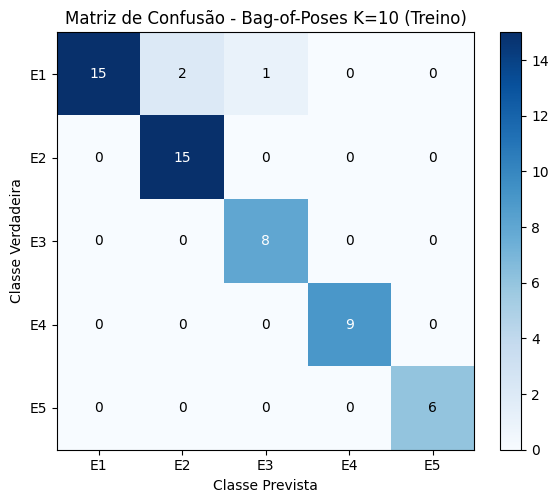

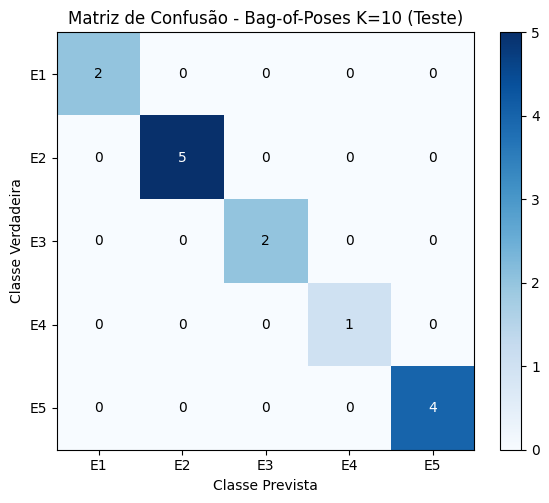

In [26]:
K = max(resultados_bop, key=lambda k: resultados_bop[k][1])
print(f"\nMelhor K selecionado para R6.b): K = {K}")

_, _, y_tr_bop, y_pred_tr, y_te_bop, y_pred_te = resultados_bop[K]

plot_e_guardar_matriz_confusao(
    y_tr_bop, y_pred_tr,
    f"Matriz de Confusão - Bag-of-Poses K={K} (Treino)",
    f"PartIII6b_K{K}_treino.jpg"
)

plot_e_guardar_matriz_confusao(
    y_te_bop, y_pred_te,
    f"Matriz de Confusão - Bag-of-Poses K={K} (Teste)",
    f"PartIII6b_K{K}_teste.jpg"
)